In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/sample_submission.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/train.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/test.csv


In [2]:
df = pd.read_csv("/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/train.csv")
df.head()

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,id,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,NaN,40.0,64173
1,1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357
2,2,SpiceJet,SG-8107,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251
3,3,NaN,0.00E+00,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0,1776
4,4,Air_India,AI-569,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0,3584


In [3]:
print(df.info())
print("=====================")

print(df.describe())
print("=====================")

categorical_cols = ['airline','flight','source', 'departure', 'stops','arrival','departure','class']


# Drop missing values
print("Missing values before drop (categorical):")
print(df[categorical_cols].isnull().sum())
df = df.dropna(subset=categorical_cols)
print(f"Shape after dropping rows with missing categorical values: {df.shape}")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           40000 non-null  int64  
 1   airline      35387 non-null  object 
 2   flight       40000 non-null  object 
 3   source       40000 non-null  object 
 4   departure    35208 non-null  object 
 5   stops        37681 non-null  object 
 6   arrival      40000 non-null  object 
 7   destination  40000 non-null  object 
 8   class        40000 non-null  object 
 9   duration     36987 non-null  float64
 10  days_left    35562 non-null  float64
 11  price        40000 non-null  int64  
dtypes: float64(2), int64(2), object(8)
memory usage: 3.7+ MB
None
                id      duration     days_left         price
count  40000.00000  36987.000000  35562.000000   40000.00000
mean   19999.50000     12.004088     26.197936   20801.49025
std    11547.14972      7.108063     13.469232   2272

# Graphs

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


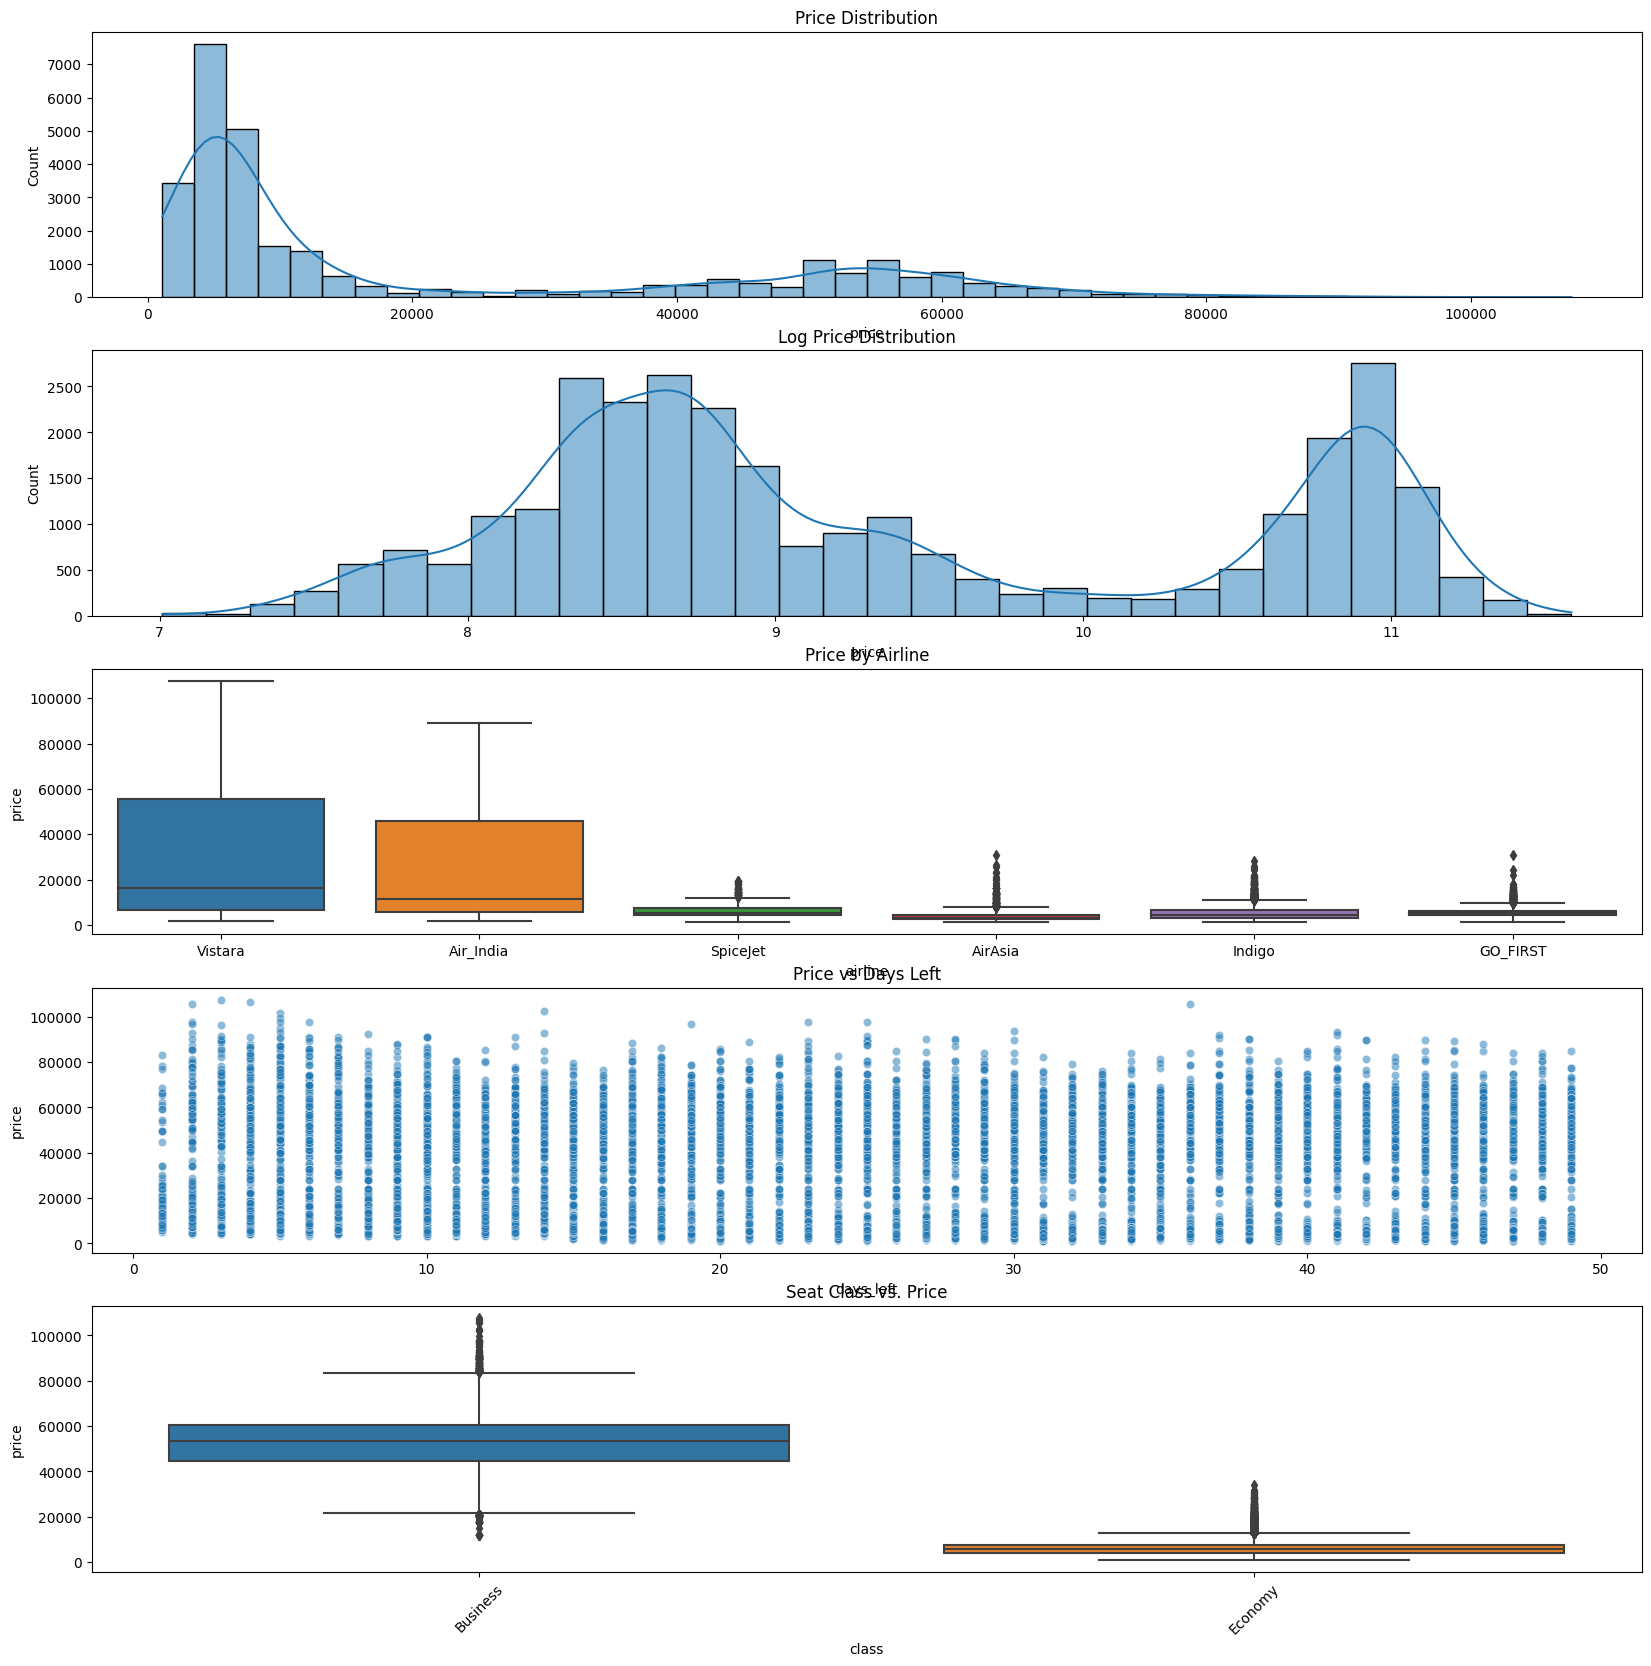

In [4]:
fig, axes = plt.subplots(5, 1, figsize=(20, 20))
sns.histplot(df['price'], kde=True, ax=axes[0])
axes[0].set_title('Price Distribution')

sns.histplot(np.log1p(df['price']), kde=True, ax=axes[1])
axes[1].set_title('Log Price Distribution')

sns.boxplot(x='airline', y='price', data=df, ax=axes[2])
plt.xticks(rotation=45)
axes[2].set_title('Price by Airline')

sns.scatterplot(x='days_left', y='price', data=df, alpha=0.5, ax=axes[3])
axes[3].set_title('Price vs Days Left')

sns.boxplot(x='class', y='price', data=df)
axes[4].set_title('Seat Class vs. Price')
# plt.tight_layout()
plt.show()

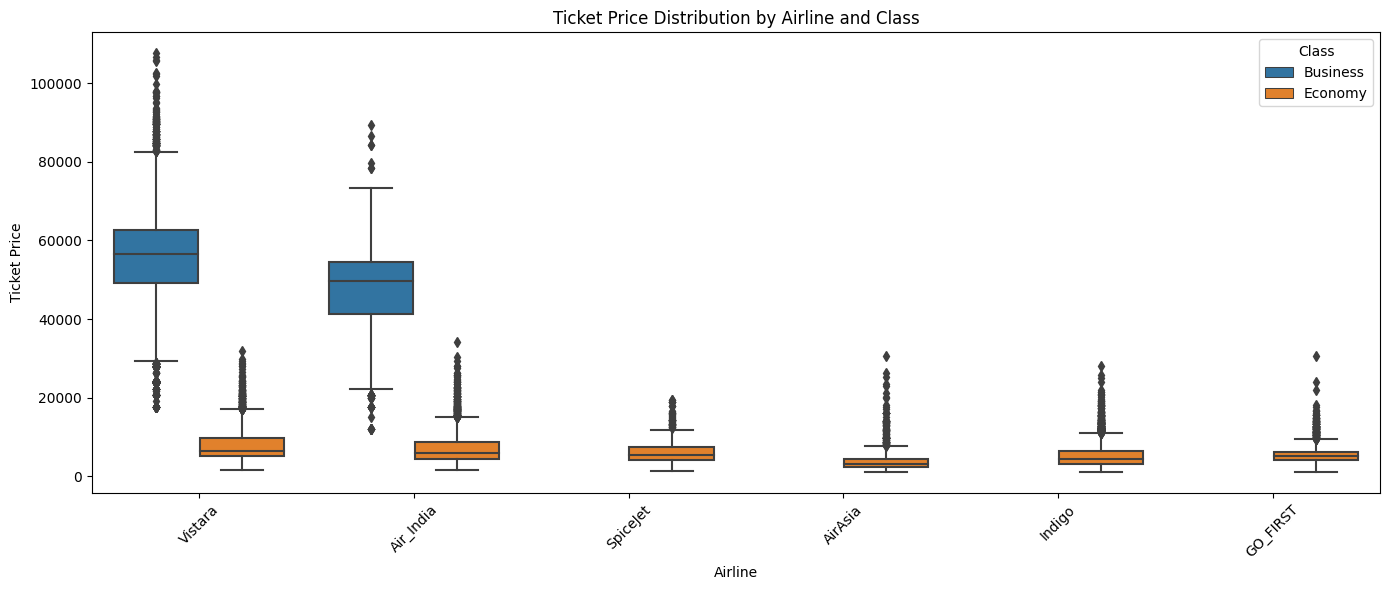

In [5]:
plt.figure(figsize=(14, 6))
sns.boxplot(x='airline', y='price', hue='class', data=df)
plt.xticks(rotation=45)
plt.title('Ticket Price Distribution by Airline and Class')
plt.xlabel('Airline')
plt.ylabel('Ticket Price')
plt.legend(title='Class')
plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


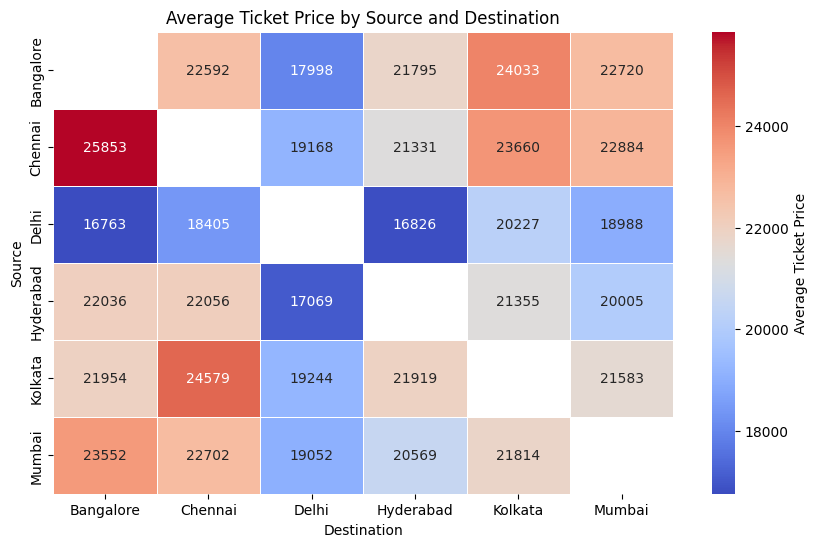

In [6]:
pivot = df.pivot_table(index='source', columns='destination', values='price', aggfunc='mean')
plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", linewidths=0.5, cmap='coolwarm', cbar_kws={'label': 'Average Ticket Price'})
plt.title('Average Ticket Price by Source and Destination')
plt.xlabel('Destination')
plt.ylabel('Source')
plt.show()


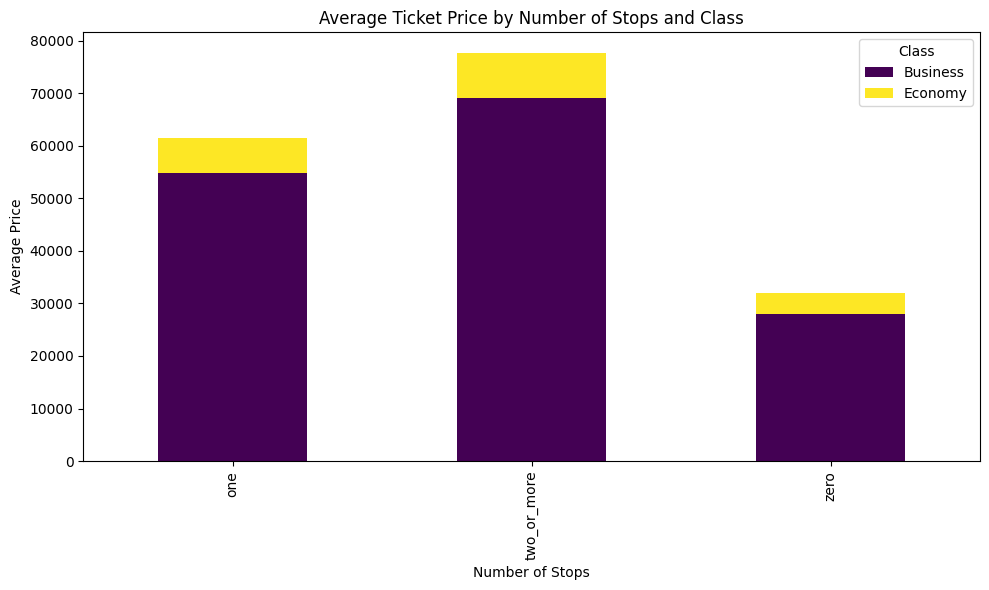

In [7]:
grouped = df.groupby(['stops', 'class'])['price'].mean().unstack()

grouped.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')
plt.title('Average Ticket Price by Number of Stops and Class')
plt.xlabel('Number of Stops')
plt.ylabel('Average Price')
plt.legend(title='Class')
plt.tight_layout()
plt.show()


# Preprocessing of Data

## Handling Outliers

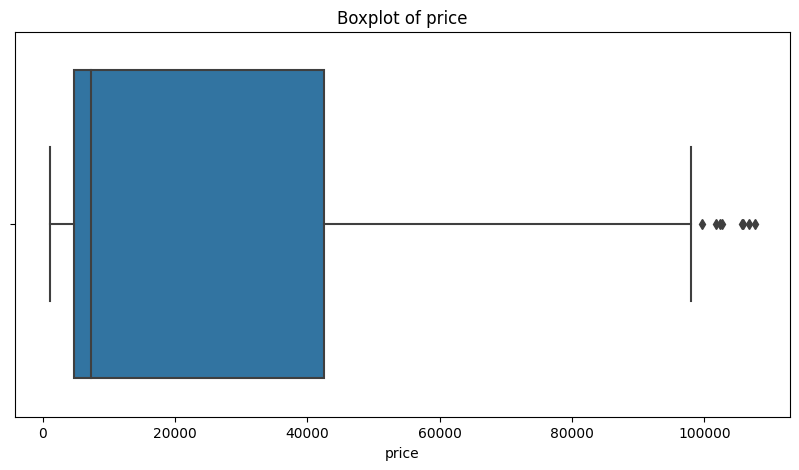

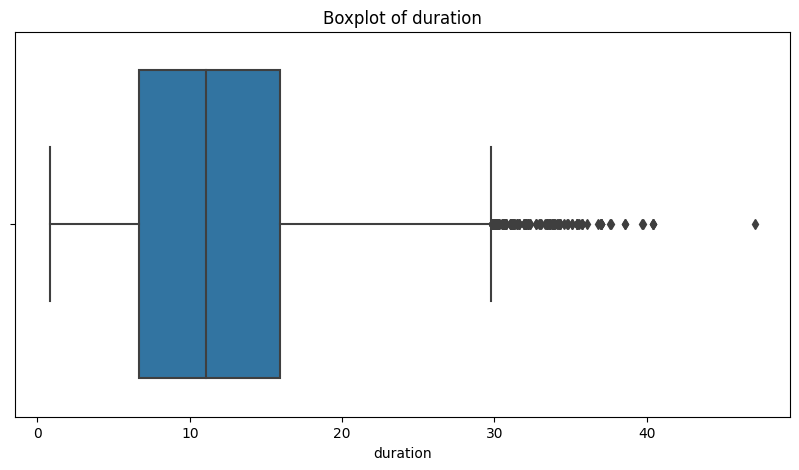

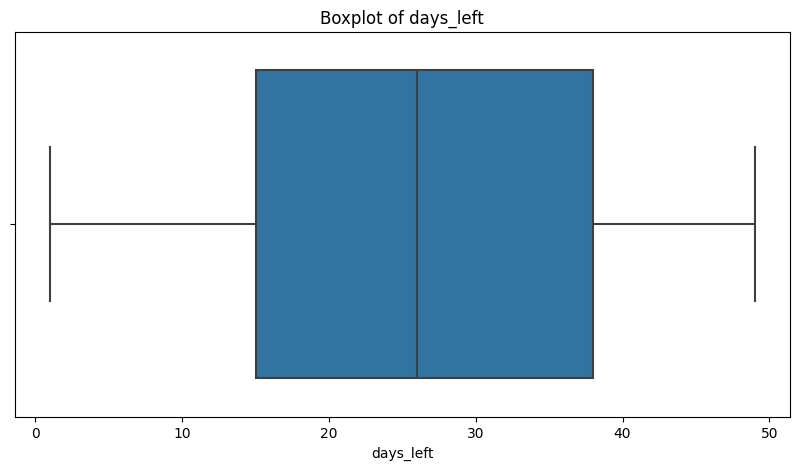

Original data shape: (29342, 12)
price - Outliers detected: 8
duration - Outliers detected: 171
days_left - Outliers detected: 0
Data shape after removing outliers: (23955, 12)


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less_equal
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)
/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressio

In [8]:

# Check for outlier

numerical_cols = ['price', 'duration', 'days_left']

for col in numerical_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

# Outlier detection using IQR
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower) | (df[column] > upper)]
    print(f"{column} - Outliers detected: {len(outliers)}")
    return df[(df[column] >= lower) & (df[column] <= upper)]

print(f"Original data shape: {df.shape}")
for col in numerical_cols:
    df = remove_outliers_iqr(df, col)
print(f"Data shape after removing outliers: {df.shape}")


## Feature Engineering and Encoding

In [9]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from category_encoders import TargetEncoder

num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_cols = [col for col in num_cols if col not in ['id', 'price']]

# Categorize categorical features by cardinality
high_cat_cols = []  # for target encoding (high cardinality)
low_cat_cols = []   # for one-hot encoding (low cardinality)

for col in df.select_dtypes(include=['object']).columns:
    if df[col].nunique() > 15:
        high_cat_cols.append(col)
    else:
        low_cat_cols.append(col)


X = df.drop(['price', 'id'], axis=1)
y = df['price']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

low_card_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', sparse_output=False,handle_unknown='ignore'))
])

high_card_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target', TargetEncoder())
])


numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ('low_card', low_card_transformer, low_cat_cols),
    ('high_card', high_card_transformer, high_cat_cols),
    ('num', numerical_pipeline, num_cols)
])


X_train_transformed = preprocessor.fit_transform(X_train, y_train)

X_val_transformed = preprocessor.transform(X_val)

print(f"Training shape: {X_train_transformed.shape}, Validation shape: {X_val_transformed.shape}")


Training shape: (19164, 31), Validation shape: (4791, 31)


# Model Training and Hyperparameter Tuning
- With Best model selection.

In [10]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

# Dictionary of models and their hyperparameters
model_grids = {
    "Linear Regression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"alpha": [0.1, 1.0, 10.0]}),
    "Lasso": (Lasso(), {"alpha": [0.001, 0.01, 0.1]}),
    "Random Forest": (RandomForestRegressor(random_state=42), {
        "n_estimators": [100],
        "max_depth": [10, None]
    }),
    "KNN": (KNeighborsRegressor(), {
        "n_neighbors": [3, 5, 7]
    }),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=42), {
        "n_estimators": [100, 150],
        "learning_rate": [0.05, 0.1]
    }),
    "XGBoost": (XGBRegressor(random_state=42, verbosity=0), {
        "n_estimators": [100, 150],
        "learning_rate": [0.05, 0.1]
    })
}

results = []
best_models = {}

# Training and evaluation loop
for name, (model, params) in model_grids.items():
    print(f"\n Training {name}...")
    if params:
        grid = GridSearchCV(model, params, cv=3, n_jobs=-1, scoring='neg_root_mean_squared_error')
        grid.fit(X_train_transformed, y_train)
        best_model = grid.best_estimator_
        print(f"Best Params: {grid.best_params_}")
    else:
        model.fit(X_train_transformed, y_train)
        best_model = model

    preds = best_model.predict(X_val_transformed)
    r2 = r2_score(y_val, preds)
    rmse = mean_squared_error(y_val, preds)

    results.append([name, r2, rmse])
    best_models[name] = best_model

# Results summary
results_df = pd.DataFrame(results, columns=["Model", "R2 Score", "RMSE"])
results_df = results_df.sort_values(by="R2 Score", ascending=False).reset_index(drop=True)
print("\n Model Comparison:")
print(results_df)



 Training Linear Regression...

 Training Ridge...
Best Params: {'alpha': 1.0}

 Training Lasso...
Best Params: {'alpha': 0.1}

 Training Random Forest...
Best Params: {'max_depth': None, 'n_estimators': 100}

 Training KNN...
Best Params: {'n_neighbors': 3}

 Training Gradient Boosting...
Best Params: {'learning_rate': 0.1, 'n_estimators': 150}

 Training XGBoost...
Best Params: {'learning_rate': 0.1, 'n_estimators': 150}

 Model Comparison:
               Model  R2 Score          RMSE
0      Random Forest  0.977724  1.147001e+07
1            XGBoost  0.972368  1.422753e+07
2  Gradient Boosting  0.961977  1.957799e+07
3              Ridge  0.916654  4.291480e+07
4              Lasso  0.916652  4.291610e+07
5  Linear Regression  0.916651  4.291637e+07
6                KNN  0.701995  1.534427e+08


## Performanace of Models

In [11]:
from sklearn.metrics import mean_absolute_error

def adjusted_r2_score(r2, n, k):
    """Compute Adjusted R²"""
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

full_results = []

for name, model in best_models.items():
    preds = model.predict(X_val_transformed)

    r2 = r2_score(y_val, preds)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    mae = mean_absolute_error(y_val, preds)
    mape = np.mean(np.abs((y_val - preds) / y_val)) * 100  # in percentage
    adj_r2 = adjusted_r2_score(r2, len(y_val), X_val_transformed.shape[1])

    full_results.append([name, r2, adj_r2, rmse, mae, mape])

# Create DataFrame
metrics_df = pd.DataFrame(full_results, columns=["Model", "R2", "Adjusted R2", "RMSE", "MAE", "MAPE (%)"])
metrics_df = metrics_df.sort_values(by="R2", ascending=False).reset_index(drop=True)
metrics_df.style.format({
    "R2": "{:.4f}",
    "Adjusted R2": "{:.4f}",
    "RMSE": "{:,.2f}",
    "MAE": "{:,.2f}",
    "MAPE (%)": "{:.2f}%"
})


,Model,R2,Adjusted R2,RMSE,MAE,MAPE (%)
0,Random Forest,0.9777,0.9776,"3,386.74","1,680.79",12.93%
1,XGBoost,0.9724,0.9722,"3,771.94","2,081.72",15.97%
2,Gradient Boosting,0.9620,0.9617,"4,424.70","2,580.02",20.02%
3,Ridge,0.9167,0.9161,"6,550.94","4,545.48",50.39%
4,Lasso,0.9167,0.9161,"6,551.04","4,545.48",50.40%
5,Linear Regression,0.9167,0.9161,"6,551.06","4,545.73",50.41%
6,KNN,0.7020,0.7001,"12,387.20","7,464.27",73.66%


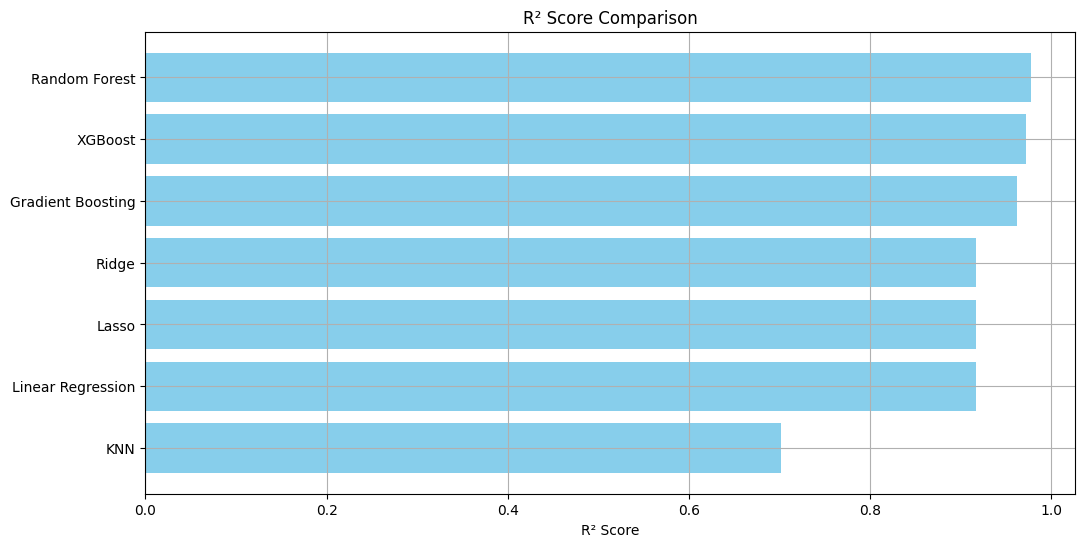

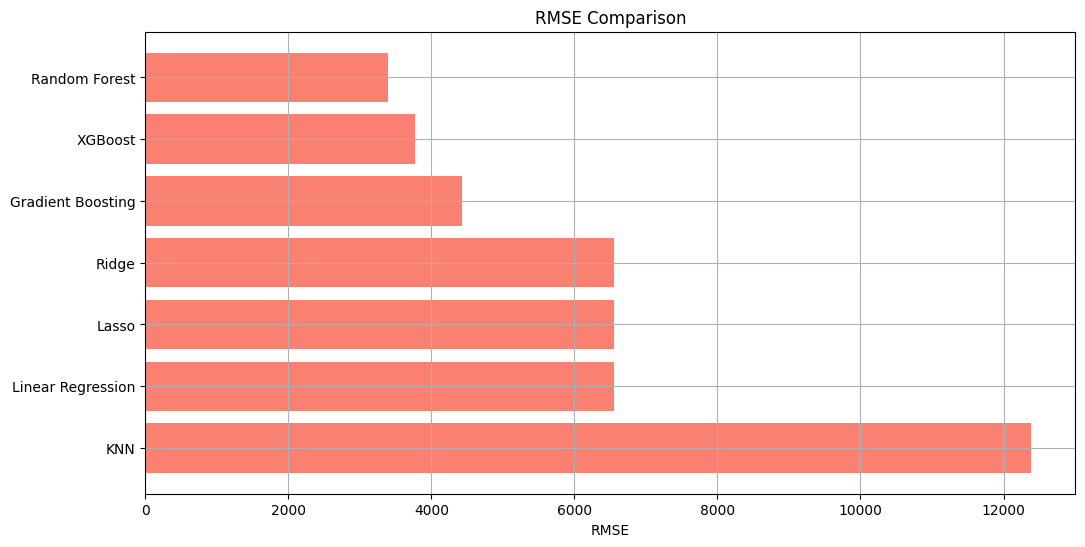

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.barh(metrics_df['Model'], metrics_df['R2'], color='skyblue')
plt.xlabel("R² Score")
plt.title("R² Score Comparison")
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.barh(metrics_df['Model'], metrics_df['RMSE'], color='salmon')
plt.xlabel("RMSE")
plt.title("RMSE Comparison")
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()


# Final Submission

In [13]:
import pandas as pd
import numpy as np

test = pd.read_csv("/kaggle/input/mlp-term-2-2025-kaggle-assignment-1/test.csv")

test_ids = test['id']
X_test = test.drop('id', axis=1)

X_test_transformed = preprocessor.transform(X_test)

final_model = best_models["Random Forest"]

test_preds = final_model.predict(X_test_transformed)

submission = pd.DataFrame({'id': test_ids, 'price': test_preds})

submission.to_csv("submission.csv", index=False)

print("submission.csv created with all 10,000 rows.")

submission.csv created with all 10,000 rows.
